# Denoising Autoencoder

An encoder maps a corrupted digit to sixteen numbers. Its decoder reconstructs clean pixel intensities from that bottleneck.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")

## Bottleneck

A narrow latent vector limits how much information can pass directly to the decoder.

In [2]:
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split
from gallery.neural import seed_cpu
from gallery.representations import probe_encoders, update_teacher

## Remove noise

Only the training images provide reconstruction targets. A fixed independent noise draw is used to score held-out images.

Held-out noisy MSE 0.0461 | Reconstructed MSE 0.0256 | PSNR 15.93 dB


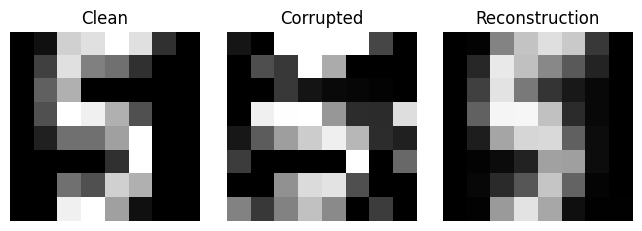

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
X = torch.tensor(train).flatten(1)
T = torch.tensor(test).flatten(1)

encoder = nn.Sequential(nn.Linear(64, 72), nn.ReLU(), nn.Linear(72, 16))
initial = copy.deepcopy(encoder)
decoder = nn.Sequential(nn.Linear(16, 72), nn.ReLU(), nn.Linear(72, 64), nn.Sigmoid())
opt = torch.optim.Adam([*encoder.parameters(), *decoder.parameters()], lr=0.002)
history = []
for epoch in range(32):
    total = 0.0
    for ids in torch.randperm(len(X)).split(64):
        clean = X[ids]
        noisy = (clean + 0.28 * torch.randn_like(clean)).clamp(0, 1)
        loss = nn.functional.mse_loss(decoder(encoder(noisy)), clean)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(ids)
    history.append(total / len(X))
with torch.no_grad():
    torch.manual_seed(99)
    noisy = (T + 0.28 * torch.randn_like(T)).clamp(0, 1)
    recovered = decoder(encoder(noisy))
    mse = (recovered - T).square().mean()
print(
    f"Held-out noisy MSE {((noisy-T)**2).mean():.4f} | Reconstructed MSE {mse:.4f} | PSNR {-10*torch.log10(mse):.2f} dB"
)
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.2), constrained_layout=True)
for ax, im, label in zip(
    axes, [T[0], noisy[0], recovered[0]], ["Clean", "Corrupted", "Reconstruction"]
):
    ax.imshow(im.reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")
plt.show()

## Frozen features

The probe and the reconstruction score measure different uses of the same latent vector.

Raw input: accuracy 0.969 | balanced accuracy 0.969 | macro F1 0.969
Random encoder: accuracy 0.880 | balanced accuracy 0.879 | macro F1 0.878
Trained encoder: accuracy 0.916 | balanced accuracy 0.915 | macro F1 0.914
Held-out mean feature SD: 1.3670 | Effective covariance rank: 6.91


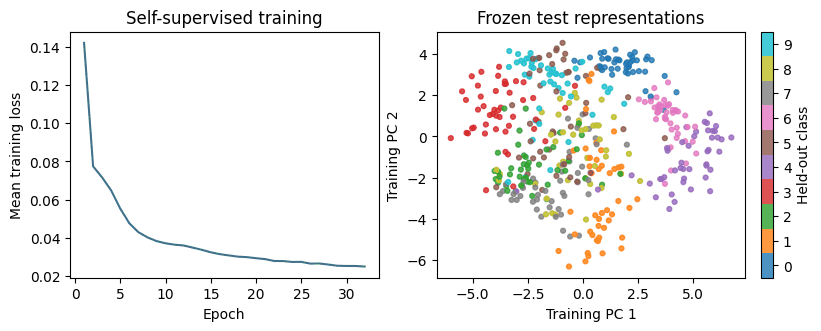

In [4]:
probe_encoders(initial, encoder, X, T, y, y_test, history)
plt.show()

## Reading the result

PSNR here uses a peak intensity of one. A smooth reconstruction may score well in mean squared error while blurring some strokes.

## References

[Vincent et al., Extracting and Composing Robust Features with Denoising Autoencoders (2008)](https://doi.org/10.1145/1390156.1390294)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Frozen probes and masked-prediction training](../gallery/representations.py)